# Phân độ bệnh võng mạc tiểu đường trên RetinaMNIST

In [1]:
!pip -q install medmnist timm

In [2]:
import os
import time
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn
from torchvision.transforms import v2

import timm
import medmnist
from medmnist import INFO
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, cohen_kappa_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = device.type == 'cuda'
print('device:', device)

device: cuda


In [3]:
# parameter
DATA_FLAG    = 'retinamnist'
IMG_SIZE     = 224             # MedMNIST+ 224x224
MODEL_NAME   = 'resnet18'
batch_size   = 32
EPOCHS       = 30
EPOCHS_HEAD  = 2
N_FOLDS      = 5
FOLD_SEED    = 0
EMA_DECAY    = 0.99
num_workers  = 2
data_root    = './data'
RESULTS_DIR  = './results_retina_v2'

QUICK = False
if QUICK:
    EPOCHS = 10
    RESULTS_DIR += '_quick'

# Chỉnh ngưỡng
W_GRID   = 2.0 ** np.arange(-2, 2.01, 0.5)
W_ROUNDS = 3

os.makedirs(data_root, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

info        = INFO[DATA_FLAG]
n_classes   = len(info['label'])
class_names = ['0 Normal', '1 Mild', '2 Moderate', '3 Severe', '4 PDR']
DataClass   = getattr(medmnist, info['python_class'])
print('Số lớp:', n_classes, '|', class_names)

Số lớp: 5 | ['0 Normal', '1 Mild', '2 Moderate', '3 Severe', '4 PDR']


## Data


In [4]:
def load_split(split):
    ds = DataClass(split=split, download=True, size=IMG_SIZE, root=data_root)
    return ds.imgs, ds.labels.flatten().astype(np.int64)

raw = {s: load_split(s) for s in ['train', 'val', 'test']}
for s, (x, y) in raw.items():
    print(f'{s:5s}: ảnh {x.shape}, nhãn {np.bincount(y, minlength=n_classes)}')

# Bảng phân bố lớp theo từng tập
dist = pd.DataFrame({s: np.bincount(y, minlength=n_classes) for s, (_, y) in raw.items()}, index=class_names)
dist['tỉ lệ train'] = (dist['train'] / dist['train'].sum()).round(3)
dist

100%|██████████| 128M/128M [00:55<00:00, 2.31MB/s]


train: ảnh (1080, 224, 224, 3), nhãn [486 128 206 194  66]
val  : ảnh (120, 224, 224, 3), nhãn [54 12 28 20  6]
test : ảnh (400, 224, 224, 3), nhãn [174  46  92  68  20]


,train,val,test,tỉ lệ train
0 Normal,486,54,174,0.450
1 Mild,128,12,46,0.119
2 Moderate,206,28,92,0.191
3 Severe,194,20,68,0.180
4 PDR,66,6,20,0.061


### Tiền xử lý Ben Graham

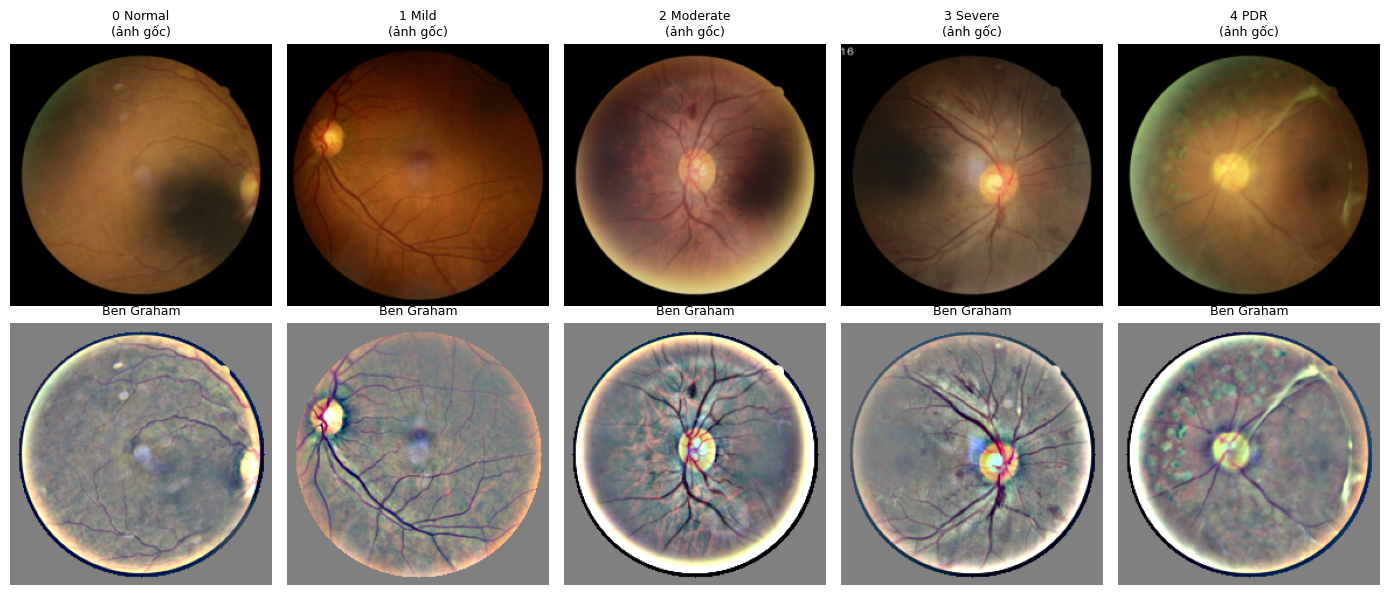

In [5]:
def ben_graham(img, sigma=IMG_SIZE / 30):
    blur = cv2.GaussianBlur(img, (0, 0), sigma)
    out = cv2.addWeighted(img, 4, blur, -4, 128)
    h, w = out.shape[:2]
    mask = np.zeros((h, w), np.uint8)
    cv2.circle(mask, (w // 2, h // 2), int(min(h, w) * 0.47), 1, -1)
    return (out * mask[..., None] + 128 * (1 - mask[..., None])).astype(np.uint8)

DATA = {
    'raw': raw,
    'ben': {s: (np.stack([ben_graham(im) for im in x]), y) for s, (x, y) in raw.items()},
}
FILL = {'raw': 0, 'ben': 128}

# So sánh ảnh gốc và ảnh sau tiền xử lý
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
x_tr, y_tr = raw['train']
for c in range(n_classes):
    i = np.where(y_tr == c)[0][0]
    axes[0, c].imshow(x_tr[i]); axes[0, c].set_title(f'{class_names[c]}\n(ảnh gốc)', fontsize=9)
    axes[1, c].imshow(DATA['ben']['train'][0][i]); axes[1, c].set_title('Ben Graham', fontsize=9)
for ax in axes.flatten():
    ax.axis('off')
plt.tight_layout()
plt.show()

In [6]:
# Mean / std theo kênh
def channel_stats(imgs, chunk=100):
    s, sq, n = np.zeros(3), np.zeros(3), 0
    for i in range(0, len(imgs), chunk):
        x = imgs[i:i + chunk].astype(np.float64) / 255
        s += x.sum((0, 1, 2)); sq += (x ** 2).sum((0, 1, 2)); n += x.shape[0] * x.shape[1] * x.shape[2]
    mean = s / n
    return mean.tolist(), np.sqrt(sq / n - mean ** 2).tolist()

STATS = {pre: channel_stats(DATA[pre]['train'][0]) for pre in DATA}
for pre, (m, s) in STATS.items():
    print(f'{pre}: mean {np.round(m, 3)}, std {np.round(s, 3)}')

raw: mean [0.395 0.242 0.145], std [0.324 0.211 0.151]
ben: mean [0.541 0.528 0.52 ], std [0.146 0.128 0.092]


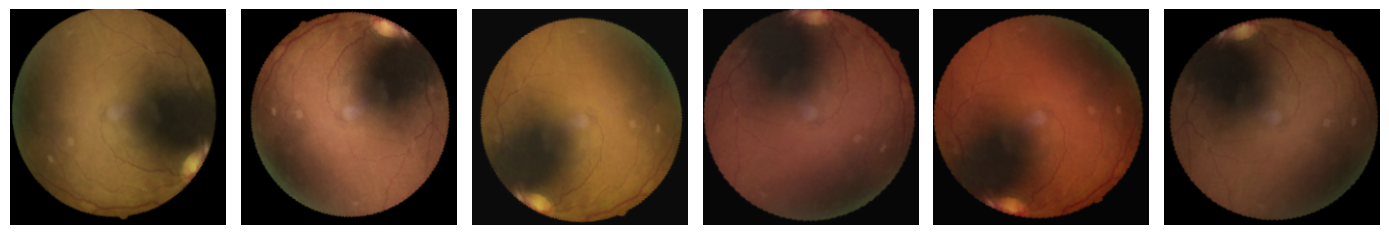

In [23]:
def make_transform(aug, pre, train):
    fill = FILL[pre]
    t = []
    if train and aug == 'basic':
        t += [v2.RandomHorizontalFlip(), v2.RandomVerticalFlip(), v2.RandomRotation(20, fill=fill)]
    elif train and aug == 'retina':
        t += [v2.RandomRotation(180, fill=fill),
              v2.RandomHorizontalFlip(),
              v2.RandomResizedCrop(IMG_SIZE, scale=(0.85, 1.0), ratio=(0.95, 1.05), antialias=True),
              v2.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.25, hue=0.05)]
    mean, std = STATS[pre]
    t += [v2.ToDtype(torch.float32, scale=True), v2.Normalize(mean, std)]
    return v2.Compose(t)


class RetinaDataset(Dataset):
    def __init__(self, imgs, labels, transform):
        self.imgs = torch.from_numpy(imgs).permute(0, 3, 1, 2)
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return self.transform(self.imgs[i]), int(self.labels[i])


# Trực quan
ds_vis = RetinaDataset(*DATA['raw']['train'], make_transform('retina', 'raw', True))
mean, std = STATS['raw']
fig, axes = plt.subplots(1, 6, figsize=(14, 2.6))
for ax in axes:
    x, y = ds_vis[0]
    img = (x * torch.tensor(std).view(3, 1, 1) + torch.tensor(mean).view(3, 1, 1)).clamp(0, 1)
    ax.imshow(img.permute(1, 2, 0)); ax.axis('off')
plt.tight_layout()
plt.show()

In [24]:
#Chia 5 fold
y_all  = np.concatenate([raw['train'][1], raw['val'][1]])
y_test = raw['test'][1]
ALL = {pre: np.concatenate([DATA[pre]['train'][0], DATA[pre]['val'][0]]) for pre in DATA}

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=0)
FOLDS = list(skf.split(np.zeros(len(y_all)), y_all))

pd.DataFrame({f'fold {k}': np.bincount(y_all[va], minlength=n_classes) for k, (_, va) in enumerate(FOLDS)},
             index=class_names)

,fold 0,fold 1,fold 2,fold 3,fold 4
0 Normal,108,108,108,108,108
1 Mild,28,28,28,28,28
2 Moderate,46,47,47,47,47
3 Severe,43,42,43,43,43
4 PDR,15,15,14,14,14


## Model

In [9]:
class GeM(nn.Module):
    def __init__(self, p=3.0, eps=1e-6):
        super().__init__()
        self.p = nn.Parameter(torch.ones(1) * p)
        self.eps = eps

    def forward(self, x):
        x = x.float().clamp(min=self.eps).pow(self.p)
        return F.adaptive_avg_pool2d(x, 1).pow(1.0 / self.p).flatten(1)


class Net(nn.Module):
    def __init__(self, backbone, n_out, pool='avg', drop=0.3):
        super().__init__()
        self.backbone = backbone
        self.pool = GeM() if pool == 'gem' else nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.head = nn.Sequential(nn.Dropout(drop), nn.Linear(backbone.num_features, n_out))

    def head_params(self):
        return list(self.pool.parameters()) + list(self.head.parameters())

    def forward(self, x):
        return self.head(self.pool(self.backbone.forward_features(x)))


def n_outputs(cfg):
    return n_classes - 1 if cfg['loss'] == 'ordinal' else n_classes


def build_model(cfg):
    backbone = timm.create_model(cfg['model'], pretrained=cfg['pretrained'], num_classes=0)
    return Net(backbone, n_outputs(cfg), pool=cfg['pool'])


print(f"{MODEL_NAME}: {sum(p.numel() for p in build_model({'model': MODEL_NAME, 'pretrained': False, 'loss': 'ce', 'pool': 'avg'}).parameters()) / 1e6:.2f}M tham số")

resnet18: 11.18M tham số


### Hàm mất mát

In [10]:
def make_criterion(cfg, class_w):
    w = class_w if cfg['class_weight'] else None
    if cfg['loss'] == 'ce':
        return nn.CrossEntropyLoss(weight=w)

    def ordinal_loss(out, y):
        target = (y[:, None] > torch.arange(n_classes - 1, device=y.device)[None]).float()
        loss = F.binary_cross_entropy_with_logits(out.float(), target, reduction='none').mean(1)
        if w is None:
            return loss.mean()
        return (loss * w[y]).sum() / w[y].sum()
    return ordinal_loss


def outputs_to_probs(out, loss_type):
    """logits -> xác suất 5 lớp (B, 5)."""
    out = out.float()
    if loss_type == 'ce':
        return out.softmax(1)
    p_gt = torch.cummin(torch.sigmoid(out), dim=1).values
    ones, zeros = torch.ones_like(p_gt[:, :1]), torch.zeros_like(p_gt[:, :1])
    ext = torch.cat([ones, p_gt, zeros], dim=1)
    return ext[:, :-1] - ext[:, 1:]


def decide(probs, w=None):
    """pred = argmax_c(w_c * p_c); w=None nghĩa là ngưỡng mặc định (argmax)."""
    w = np.ones(n_classes) if w is None else np.asarray(w)
    return (probs * w).argmax(-1)


def compute_metrics(probs, y, w=None):
    pred = decide(probs, w)
    try:
        auc = roc_auc_score(y, probs, multi_class='ovr', average='macro', labels=list(range(n_classes)))
    except ValueError:
        auc = np.nan
    return {'ACC': accuracy_score(y, pred),
            'AUC': auc,
            'QWK': cohen_kappa_score(y, pred, weights='quadratic'),
            'Macro-F1': f1_score(y, pred, average='macro', labels=list(range(n_classes)), zero_division=0),
            'AUC chuyển khám': roc_auc_score(y >= 2, probs[:, 2:].sum(1))}

## Cấu hình ablation

In [26]:
CONFIGS = []
cfg = dict(name='S0', label='ResNet-18', desc='ResNet-18 (224)', parent=None,
           model=MODEL_NAME, pretrained=False,     # kiến trúc
           preprocess='raw', aug='basic',          # dữ liệu
           loss='ce', class_weight=False,          # hàm mất mát
           pool='avg', ema=False,                  # chi tiết huấn luyện
           lr=1e-3, wd=1e-4, epochs_head=0)        # train từ đầu
CONFIGS.append(cfg)

def step(name, label, desc, **changes):
    global cfg
    cfg = {**cfg, 'name': name, 'label': label, 'desc': desc, 'parent': cfg['name'], **changes}
    CONFIGS.append(cfg)

step('S1', 'Transfer learning', f'+ {MODEL_NAME} pretrained ImageNet',
     pretrained=True, lr=3e-4, wd=1e-2, epochs_head=EPOCHS_HEAD)
step('S2', 'Augmentation', '+ augmentation', aug='retina')       # xoay 360°, crop, đổi màu
step('S3', 'Ben Graham', '+ tiền xử lý Ben Graham', preprocess='ben')
step('S4', 'Trọng số lớp', '+ trọng số lớp', class_weight=True)
step('S5', 'Ordinal loss', 'ordinal loss thay cross-entropy', loss='ordinal')
step('S6', 'GeM + EMA', '+ GeM pooling + EMA', pool='gem', ema=True)

CFG  = {c['name']: c for c in CONFIGS}
MAIN = [c['name'] for c in CONFIGS]
pd.DataFrame(CONFIGS).set_index('name')

,label,desc,parent,model,pretrained,preprocess,aug,loss,class_weight,pool,ema,lr,wd,epochs_head
name,,,,,,,,,,,,,,
S0,ResNet-18,ResNet-18 (224),None,resnet18,False,raw,basic,ce,False,avg,False,0.0010,0.0001,0
S1,Transfer learning,+ resnet18 pretrained ImageNet,S0,resnet18,True,raw,basic,ce,False,avg,False,0.0003,0.0100,2
S2,Augmentation,+ augmentation,S1,resnet18,True,raw,retina,ce,False,avg,False,0.0003,0.0100,2
S3,Ben Graham,+ tiền xử lý Ben Graham,S2,resnet18,True,ben,retina,ce,False,avg,False,0.0003,0.0100,2
S4,Trọng số lớp,+ trọng số lớp,S3,resnet18,True,ben,retina,ce,True,avg,False,0.0003,0.0100,2
S5,Ordinal loss,ordinal loss thay cross-entropy,S4,resnet18,True,ben,retina,ordinal,True,avg,False,0.0003,0.0100,2
S6,GeM + EMA,+ GeM pooling + EMA,S5,resnet18,True,ben,retina,ordinal,True,gem,True,0.0003,0.0100,2


## Training

In [12]:
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)


@torch.no_grad()
def predict(model, loader, loss_type):
    model.eval()
    all_probs, all_y = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            out = model(x)
        all_probs.append(outputs_to_probs(out, loss_type).cpu()); all_y.append(y)
    return torch.cat(all_probs).numpy(), torch.cat(all_y).numpy()


def train_one_epoch(model, loader, criterion, optimizer, scaler, loss_type, ema=None, freeze_backbone=False):
    model.train()
    if freeze_backbone:
        model.backbone.eval()
    running_loss, running_correct, total = 0.0, 0, 0
    for inputs, labels in loader:
        inputs, labels = inputs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            outputs = model(inputs)
            loss = criterion(outputs.float(), labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update()
        if ema is not None:
            ema.update_parameters(model)
        running_loss += loss.item() * len(labels)
        pred = decide(outputs_to_probs(outputs.detach(), loss_type).cpu().numpy())
        running_correct += (pred == labels.cpu().numpy()).sum()
        total += len(labels)
    return running_loss / total, 100 * running_correct / total

In [13]:
def run_experiment(cfg, k, tag):
    path = os.path.join(RESULTS_DIR, f'{tag}.npz')
    hist_path = os.path.join(RESULTS_DIR, f'{tag}_history.csv')
    if os.path.exists(path):
        print(f'[{tag}] đã có kết quả, nạp lại')
        z = np.load(path)
        r = {key: z[key] for key in ['probs', 'val_probs', 'val_y', 'y']}
        r['history'] = pd.read_csv(hist_path) if os.path.exists(hist_path) else None
        return r

    seed_everything(FOLD_SEED)
    pre, lt = cfg['preprocess'], cfg['loss']
    tr_idx, va_idx = FOLDS[k]
    tr_x, tr_y = ALL[pre][tr_idx], y_all[tr_idx]
    va_x, va_y = ALL[pre][va_idx], y_all[va_idx]
    te_x, te_y = DATA[pre]['test']
    train_set = RetinaDataset(tr_x, tr_y, make_transform(cfg['aug'], pre, train=True))
    val_set   = RetinaDataset(va_x, va_y, make_transform(cfg['aug'], pre, train=False))
    test_set  = RetinaDataset(te_x, te_y, make_transform(cfg['aug'], pre, train=False))

    g = torch.Generator(); g.manual_seed(FOLD_SEED)
    loader_kw = dict(batch_size=batch_size, num_workers=num_workers, pin_memory=USE_AMP, worker_init_fn=seed_worker)
    trainloader = DataLoader(train_set, shuffle=True, drop_last=True, generator=g, **loader_kw)
    valloader   = DataLoader(val_set, shuffle=False, **loader_kw)
    testloader  = DataLoader(test_set, shuffle=False, **loader_kw)

    # Trọng số lớp
    counts = np.bincount(tr_y, minlength=n_classes)
    class_w = torch.tensor(len(tr_y) / (n_classes * np.maximum(counts, 1)), dtype=torch.float32, device=device)

    model = build_model(cfg).to(device)
    criterion = make_criterion(cfg, class_w)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    history, ema = [], None

    def log_epoch(ep, stage, tr_loss, tr_acc, lr, t0):
        eval_model = ema.module if ema is not None else model
        vp, vy = predict(eval_model, valloader, lt)
        m = compute_metrics(vp, vy)                              # ngưỡng mặc định, chỉ để theo dõi
        history.append({'epoch': ep, 'stage': stage, 'train_loss': tr_loss, 'train_acc': tr_acc,
                        'val_acc': 100 * m['ACC'], 'val_qwk': m['QWK']})
        print(f"[{tag}] Epoch [{ep}/{EPOCHS}] ({stage}) Loss: {tr_loss:.4f}, Accuracy: {tr_acc:.2f}%, "
              f"Val Accuracy: {100 * m['ACC']:.2f}%, Val QWK: {m['QWK']:.4f}, LR: {lr:.1e}, Time: {time.time() - t0:.0f}s")

    # Gd 1: đóng băng backbone, chỉ train pooling + head
    if cfg['epochs_head'] > 0:
        for p in model.backbone.parameters():
            p.requires_grad = False
        optimizer = AdamW(model.head_params(), lr=1e-3, weight_decay=cfg['wd'])
        for ep in range(cfg['epochs_head']):
            t0 = time.time()
            tr_loss, tr_acc = train_one_epoch(model, trainloader, criterion, optimizer, scaler, lt, freeze_backbone=True)
            log_epoch(ep + 1, 'head', tr_loss, tr_acc, 1e-3, t0)
        for p in model.backbone.parameters():
            p.requires_grad = True

    # Gd2: train toàn bộ mạng
    n_ft = EPOCHS - cfg['epochs_head']
    optimizer = AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])
    scheduler = CosineAnnealingLR(optimizer, T_max=n_ft)
    if cfg['ema']:
        ema = AveragedModel(model, multi_avg_fn=get_ema_multi_avg_fn(EMA_DECAY), use_buffers=True)
    for ep in range(n_ft):
        t0 = time.time()
        lr = scheduler.get_last_lr()[0]
        tr_loss, tr_acc = train_one_epoch(model, trainloader, criterion, optimizer, scaler, lt, ema=ema)
        scheduler.step()
        log_epoch(cfg['epochs_head'] + ep + 1, 'full', tr_loss, tr_acc, lr, t0)

    # Mô hình cuối
    final = ema.module if ema is not None else model
    r = {'probs': predict(final, testloader, lt)[0],
         'val_probs': predict(final, valloader, lt)[0], 'val_y': va_y, 'y': te_y}
    np.savez(path, **r)
    r['history'] = pd.DataFrame(history)
    r['history'].to_csv(hist_path, index=False)
    del model, ema, final
    if USE_AMP:
        torch.cuda.empty_cache()
    return r

In [14]:
# Chạy S0 -> S6
results = {}
for cfg in CONFIGS:
    for k in range(N_FOLDS):
        tag = f"{cfg['name']}_fold{k}"
        print(f"\n========== {tag}: {cfg['desc']} ==========")
        results[(cfg['name'], k)] = run_experiment(cfg, k, tag)

# out-of-fold
OOF, TEST = {}, {}
for name in MAIN:
    oof = np.full((len(y_all), n_classes), np.nan)
    for k, (_, va) in enumerate(FOLDS):
        r = results[(name, k)]
        assert np.array_equal(r['val_y'], y_all[va]), f'{name} fold {k}: cách chia fold không khớp'
        assert np.array_equal(r['y'], y_test), f'{name} fold {k}: nhãn test không khớp'
        oof[va] = r['val_probs']
    assert not np.isnan(oof).any()
    OOF[name]  = oof
    TEST[name] = np.stack([results[(name, k)]['probs'] for k in range(N_FOLDS)])   # (5, 400, 5)
print('Đã có đủ dự đoán cho:', MAIN)


========== S0_fold0: ResNet-18 (224), train từ đầu ==========
[S0_fold0] Epoch [1/30] (full) Loss: 1.2970, Accuracy: 45.52%, Val Accuracy: 37.08%, Val QWK: 0.2862, LR: 1.0e-03, Time: 6s
[S0_fold0] Epoch [2/30] (full) Loss: 1.1665, Accuracy: 52.40%, Val Accuracy: 47.08%, Val QWK: 0.1908, LR: 1.0e-03, Time: 2s
[S0_fold0] Epoch [3/30] (full) Loss: 1.1767, Accuracy: 50.62%, Val Accuracy: 52.08%, Val QWK: 0.4396, LR: 9.9e-04, Time: 2s
[S0_fold0] Epoch [4/30] (full) Loss: 1.1545, Accuracy: 52.60%, Val Accuracy: 50.42%, Val QWK: 0.4452, LR: 9.8e-04, Time: 2s
[S0_fold0] Epoch [5/30] (full) Loss: 1.1579, Accuracy: 51.88%, Val Accuracy: 51.67%, Val QWK: 0.4397, LR: 9.6e-04, Time: 2s
[S0_fold0] Epoch [6/30] (full) Loss: 1.1498, Accuracy: 51.98%, Val Accuracy: 48.33%, Val QWK: 0.4032, LR: 9.3e-04, Time: 2s
[S0_fold0] Epoch [7/30] (full) Loss: 1.1403, Accuracy: 51.46%, Val Accuracy: 53.75%, Val QWK: 0.4585, LR: 9.0e-04, Time: 2s
[S0_fold0] Epoch [8/30] (full) Loss: 1.1406, Accuracy: 52.19%, Val Ac

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

[S1_fold0] Epoch [1/30] (head) Loss: 1.4510, Accuracy: 40.21%, Val Accuracy: 45.00%, Val QWK: 0.0000, LR: 1.0e-03, Time: 2s
[S1_fold0] Epoch [2/30] (head) Loss: 1.3126, Accuracy: 46.88%, Val Accuracy: 45.83%, Val QWK: 0.0244, LR: 1.0e-03, Time: 2s
[S1_fold0] Epoch [3/30] (full) Loss: 1.2652, Accuracy: 47.60%, Val Accuracy: 52.08%, Val QWK: 0.2511, LR: 3.0e-04, Time: 2s
[S1_fold0] Epoch [4/30] (full) Loss: 1.1056, Accuracy: 56.04%, Val Accuracy: 55.42%, Val QWK: 0.4281, LR: 3.0e-04, Time: 2s
[S1_fold0] Epoch [5/30] (full) Loss: 1.0337, Accuracy: 58.65%, Val Accuracy: 57.92%, Val QWK: 0.5467, LR: 3.0e-04, Time: 2s
[S1_fold0] Epoch [6/30] (full) Loss: 0.9603, Accuracy: 60.42%, Val Accuracy: 61.25%, Val QWK: 0.6541, LR: 2.9e-04, Time: 2s
[S1_fold0] Epoch [7/30] (full) Loss: 0.9085, Accuracy: 61.98%, Val Accuracy: 62.50%, Val QWK: 0.6799, LR: 2.9e-04, Time: 2s
[S1_fold0] Epoch [8/30] (full) Loss: 0.8612, Accuracy: 64.06%, Val Accuracy: 59.17%, Val QWK: 0.6238, LR: 2.8e-04, Time: 2s
[S1_fold

## Chỉnh ngưỡng

In [27]:
def tune_weights(probs, y, grid=W_GRID, n_rounds=W_ROUNDS):
    score = lambda w: f1_score(y, decide(probs, w), average='macro', labels=list(range(n_classes)), zero_division=0)
    w = np.ones(n_classes)
    best = score(w)
    for _ in range(n_rounds):
        changed = False
        for c in range(1, n_classes):
            for g in grid:
                w_try = w.copy(); w_try[c] = g
                s = score(w_try)
                if s > best + 1e-9:
                    best, w, changed = s, w_try, True
        if not changed:
            break
    return w

W = {name: tune_weights(OOF[name], y_all) for name in MAIN}
w_table = pd.DataFrame(W, index=[f'w{c} ({class_names[c]})' for c in range(n_classes)]).T
w_table.index = [f"{n} {CFG[n]['label']}" for n in MAIN]
w_table.to_csv(os.path.join(RESULTS_DIR, 'threshold_weights.csv'))
w_table.round(3)

,w0 (0 Normal),w1 (1 Mild),w2 (2 Moderate),w3 (3 Severe),w4 (4 PDR)
S0 ResNet-18,1.0,1.414,1.000,1.000,2.000
S1 Transfer learning,1.0,2.000,1.414,1.000,2.000
S2 Augmentation,1.0,2.000,1.414,1.000,4.000
S3 Ben Graham,1.0,2.000,1.414,1.414,4.000
S4 Trọng số lớp,1.0,0.500,0.707,1.000,0.354
S5 Ordinal loss,1.0,1.000,1.000,1.000,1.000
S6 GeM + EMA,1.0,0.500,1.000,1.000,0.707


## Kết quả trên tập test


In [28]:
METRICS = ['ACC', 'AUC', 'QWK', 'Macro-F1', 'AUC chuyển khám']

FOLD_M = {name: pd.DataFrame([compute_metrics(TEST[name][k], y_test, W[name]) for k in range(N_FOLDS)])
          for name in MAIN}

def mean_std(s):
    return f'{s.mean():.4f} ± {s.std(ddof=1):.4f}'

table = pd.DataFrame({m: [mean_std(FOLD_M[n][m]) for n in MAIN] for m in METRICS},
                     index=[f"{n} {CFG[n]['label']}" for n in MAIN])
table.insert(0, 'Mô tả', [CFG[n]['desc'] for n in MAIN])
table.to_csv(os.path.join(RESULTS_DIR, 'ablation_table.csv'))
table

,Mô tả,ACC,AUC,QWK,Macro-F1,AUC chuyển khám
S0 ResNet-18,ResNet-18 (224),0.5195 ± 0.0099,0.7380 ± 0.0086,0.5595 ± 0.0153,0.3792 ± 0.0122,0.8242 ± 0.0052
S1 Transfer learning,+ resnet18 pretrained ImageNet,0.6150 ± 0.0100,0.8585 ± 0.0058,0.7473 ± 0.0101,0.5167 ± 0.0161,0.9199 ± 0.0065
S2 Augmentation,+ augmentation,0.6285 ± 0.0068,0.8734 ± 0.0042,0.7503 ± 0.0184,0.5408 ± 0.0078,0.9401 ± 0.0042
S3 Ben Graham,+ tiền xử lý Ben Graham,0.6010 ± 0.0152,0.8650 ± 0.0090,0.7693 ± 0.0213,0.5119 ± 0.0234,0.9491 ± 0.0062
S4 Trọng số lớp,+ trọng số lớp,0.6290 ± 0.0144,0.8712 ± 0.0045,0.8047 ± 0.0112,0.5250 ± 0.0203,0.9478 ± 0.0039
S5 Ordinal loss,ordinal loss thay cross-entropy,0.5995 ± 0.0080,0.8762 ± 0.0036,0.8046 ± 0.0075,0.5511 ± 0.0153,0.9536 ± 0.0019
S6 GeM + EMA,+ GeM pooling + EMA,0.6410 ± 0.0215,0.8730 ± 0.0028,0.7973 ± 0.0155,0.5749 ± 0.0263,0.9511 ± 0.0033


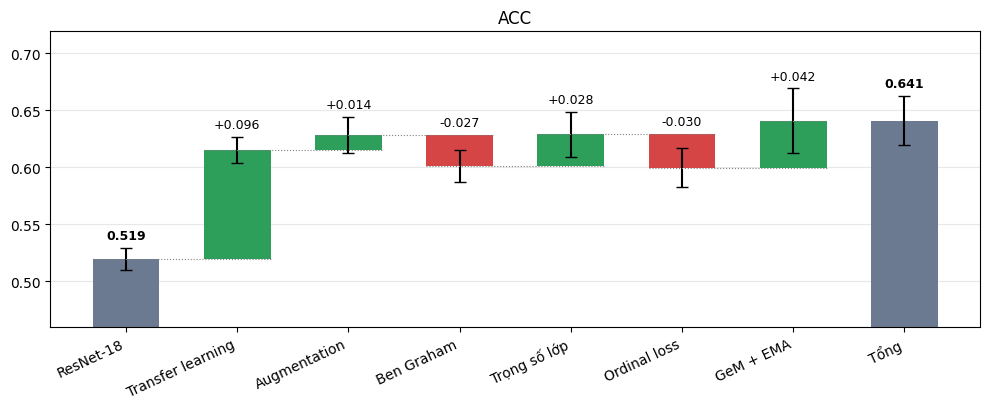

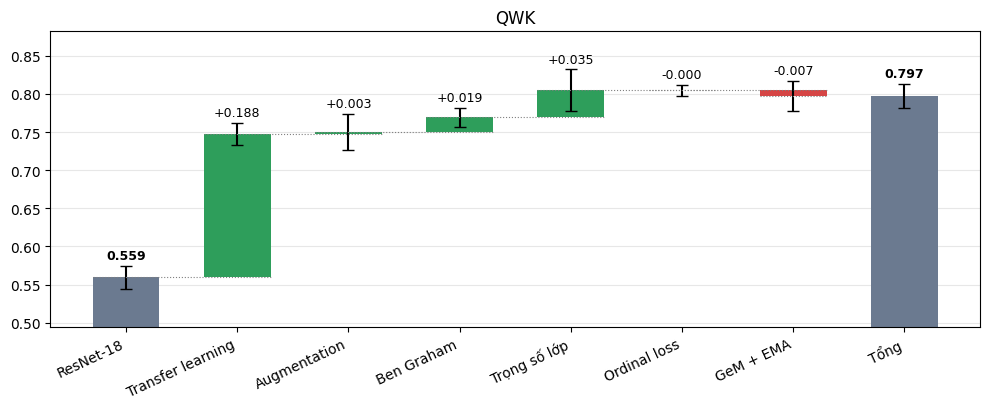

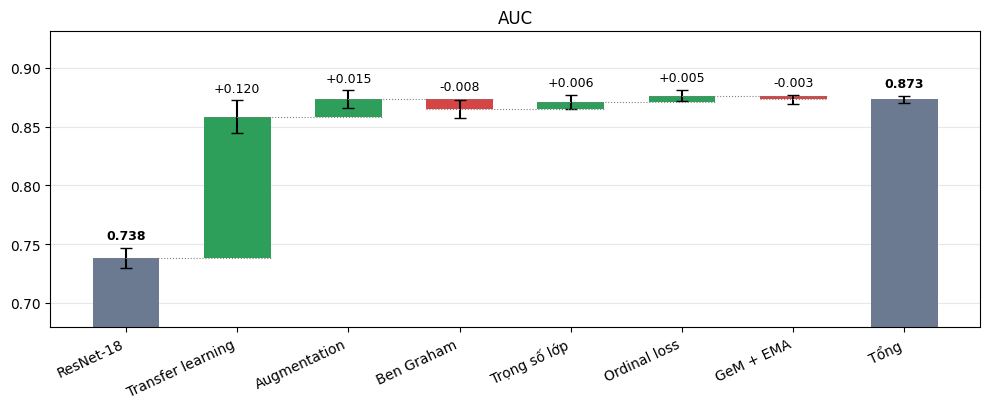

,ACC,AUC,QWK,Macro-F1,AUC chuyển khám
S1 Transfer learning,+0.0955 ± 0.0114,+0.1205 ± 0.0137,+0.1878 ± 0.0144,+0.1375 ± 0.0141,+0.0957 ± 0.0107
S2 Augmentation,+0.0135 ± 0.0159,+0.0149 ± 0.0073,+0.0030 ± 0.0234,+0.0241 ± 0.0224,+0.0202 ± 0.0102
S3 Ben Graham,-0.0275 ± 0.0143,-0.0084 ± 0.0080,+0.0190 ± 0.0122,-0.0289 ± 0.0210,+0.0090 ± 0.0060
S4 Trọng số lớp,+0.0280 ± 0.0196,+0.0062 ± 0.0059,+0.0354 ± 0.0273,+0.0131 ± 0.0233,-0.0013 ± 0.0055
S5 Ordinal loss,-0.0295 ± 0.0173,+0.0050 ± 0.0048,-0.0001 ± 0.0077,+0.0261 ± 0.0347,+0.0058 ± 0.0044
S6 GeM + EMA,+0.0415 ± 0.0283,-0.0032 ± 0.0038,-0.0073 ± 0.0193,+0.0238 ± 0.0327,-0.0025 ± 0.0038


In [34]:
#waterfall
UP, DOWN, ABS = '#2e9e5b', '#d64545', '#6b7a90'

def deltas(metric):
    return {n: FOLD_M[n][metric] - FOLD_M[p][metric] for p, n in zip(MAIN[:-1], MAIN[1:])}

def waterfall(metric, ax):
    means = [FOLD_M[n][metric].mean() for n in MAIN]
    d = deltas(metric)
    labels = [CFG[n]['label'] for n in MAIN] + ['Tổng']
    x = np.arange(len(labels))

    s_first, s_last = FOLD_M[MAIN[0]][metric].std(ddof=1), FOLD_M[MAIN[-1]][metric].std(ddof=1)
    tops = [means[0] + s_first, means[-1] + s_last]

    def absolute_bar(i, v, s):
        ax.bar(i, v, yerr=s, capsize=4, color=ABS, width=0.6)
        ax.text(i, v + s + 0.005, f'{v:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

    absolute_bar(0, means[0], s_first)
    for i, n in enumerate(MAIN[1:], start=1):
        dm, ds = d[n].mean(), d[n].std(ddof=1)
        ax.bar(i, dm, bottom=means[i - 1], yerr=ds, capsize=4, width=0.6, color=UP if dm >= 0 else DOWN)
        ax.plot([i - 1.3, i + 0.3], [means[i - 1]] * 2, color='gray', lw=0.8, ls=':')
        top = max(means[i - 1], means[i] + ds)
        ax.text(i, top + 0.005, f'{dm:+.3f}', ha='center', va='bottom', fontsize=9)
        tops.append(top)
    ax.plot([len(MAIN) - 1.3, len(MAIN) - 0.7], [means[-1]] * 2, color='gray', lw=0.8, ls=':')
    absolute_bar(len(MAIN), means[-1], s_last)

    lows = [m - s for m, s in [(means[0], s_first), (means[-1], s_last)]] + \
           [means[i] - d[n].std(ddof=1) for i, n in enumerate(MAIN[1:], start=1)] + means
    ax.set_ylim(max(0, min(lows) - 0.05), max(tops) + 0.05)
    ax.set_xticks(x); ax.set_xticklabels(labels, rotation=25, ha='right')
    ax.set_title(f'{metric}')
    ax.grid(axis='y', alpha=0.3); ax.set_axisbelow(True)

for metric in ['ACC', 'QWK', 'AUC']:
    fig, ax = plt.subplots(figsize=(10, 4.2))
    waterfall(metric, ax)
    plt.tight_layout()
    plt.show()

# Bảng Δ (trung bình ± std theo cặp fold) cho mọi chỉ số
delta_rows = []
for p, n in zip(MAIN[:-1], MAIN[1:]):
    row = {'Bước': n, 'Giải pháp': CFG[n]['label'], 'so với': p}
    for m in METRICS:
        dk = FOLD_M[n][m] - FOLD_M[p][m]
        row[f'Δ {m}'] = dk.mean()
        row[f'Δ {m} std'] = dk.std(ddof=1)
    delta_rows.append(row)
delta_table = pd.DataFrame(delta_rows).set_index('Bước')
delta_table.to_csv(os.path.join(RESULTS_DIR, 'ablation_deltas.csv'))
pd.DataFrame({m: [f"{r[f'Δ {m}']:+.4f} ± {r[f'Δ {m} std']:.4f}" for _, r in delta_table.iterrows()] for m in METRICS},
             index=[f"{n} {CFG[n]['label']}" for n in delta_table.index])

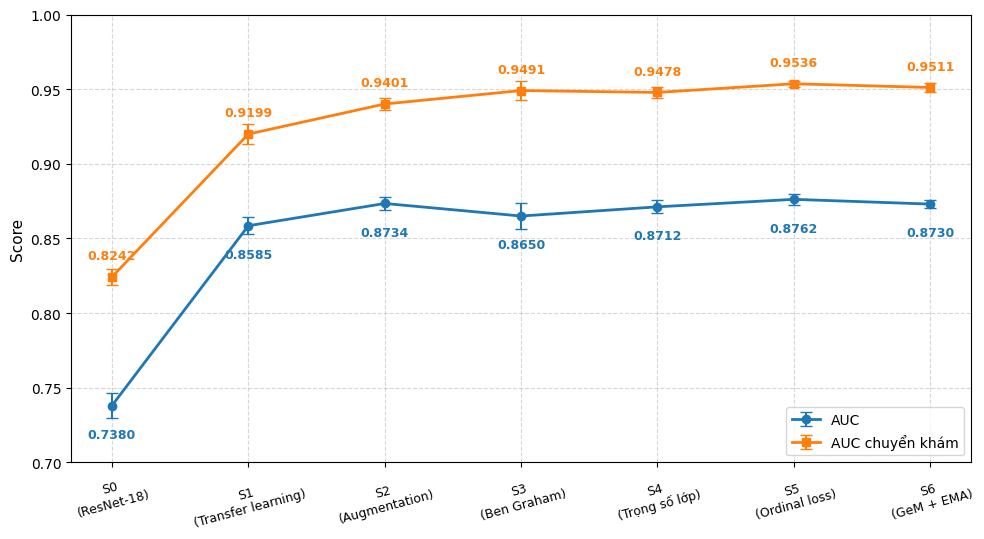

In [42]:
import matplotlib.pyplot as plt
import numpy as np

# get data
steps = MAIN
labels = [f"{n}\n({CFG[n]['label']})" for n in steps]

auc_means = [FOLD_M[n]['AUC'].mean() for n in steps]
auc_stds = [FOLD_M[n]['AUC'].std(ddof=1) for n in steps]

auc_ck_means = [FOLD_M[n]['AUC chuyển khám'].mean() for n in steps]
auc_ck_stds = [FOLD_M[n]['AUC chuyển khám'].std(ddof=1) for n in steps]

plt.figure(figsize=(10, 5.5))

plt.errorbar(steps, auc_means, yerr=auc_stds, fmt='-o', capsize=4, elinewidth=1.5,
             linewidth=2, label='AUC', color='#1f77b4')

plt.errorbar(steps, auc_ck_means, yerr=auc_ck_stds, fmt='-s', capsize=4, elinewidth=1.5,
             linewidth=2, label='AUC chuyển khám', color='#ff7f0e')

for i, (mean_val, ck_val) in enumerate(zip(auc_means, auc_ck_means)):
    plt.text(i, mean_val - 0.015, f"{mean_val:.4f}", ha='center', va='top', color='#1f77b4', fontsize=9, fontweight='bold')
    plt.text(i, ck_val + 0.01, f"{ck_val:.4f}", ha='center', va='bottom', color='#ff7f0e', fontsize=9, fontweight='bold')

plt.xticks(np.arange(len(steps)), labels, rotation=15, fontsize=9)
plt.ylabel('Score', fontsize=11)
plt.ylim(0.7, 1.0)
plt.grid(axis='both', linestyle='--', alpha=0.5)
plt.legend(loc='lower right', fontsize=10)
plt.tight_layout()
plt.show()

### Đường cong huấn luyện

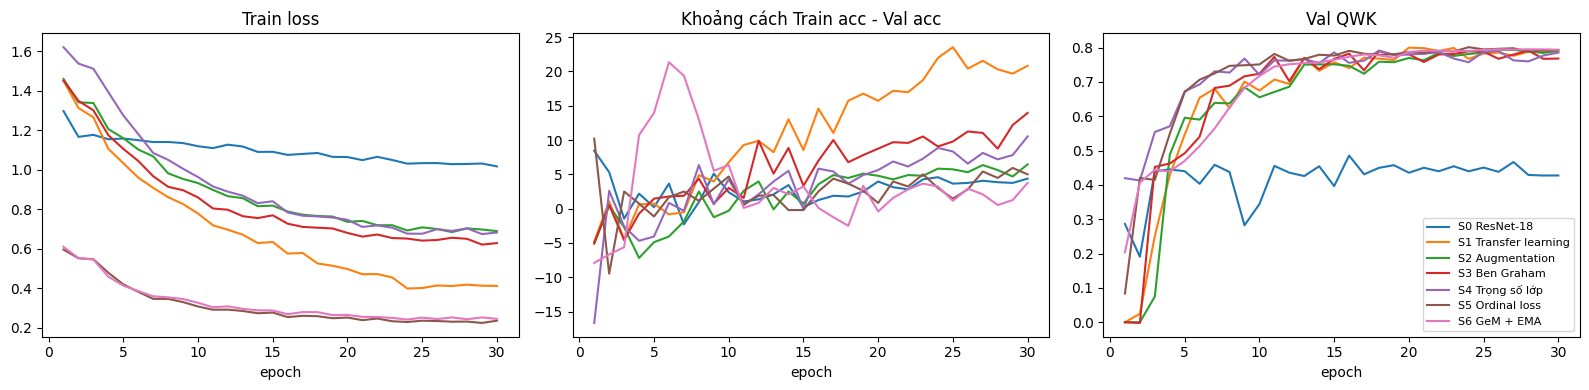

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for n in MAIN:
    h = results[(n, 0)]['history']
    if h is None:
        print(f'{n}: không có file history'); continue
    lab = f"{n} {CFG[n]['label']}"
    axes[0].plot(h['epoch'], h['train_loss'], label=lab)
    axes[1].plot(h['epoch'], h['train_acc'] - h['val_acc'], label=lab)
    axes[2].plot(h['epoch'], h['val_qwk'], label=lab)
axes[0].set_title('Train loss')
axes[1].set_title('Khoảng cách Train acc - Val acc')
axes[2].set_title('Val QWK')
for ax in axes:
    ax.set_xlabel('epoch')
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Phân bố dự đoán

In [20]:
PRED = {n: decide(TEST[n], W[n]) for n in MAIN}          # dự đoán đã chỉnh ngưỡng
dist_pred = pd.DataFrame(
    {'Thật': np.bincount(y_test, minlength=n_classes),
     **{f"{n} {CFG[n]['label']}": np.bincount(PRED[n].ravel(), minlength=n_classes) / N_FOLDS for n in MAIN}},
    index=class_names).T
dist_pred['độ TB dự đoán'] = dist_pred[class_names].values @ np.arange(n_classes) / len(y_test)
dist_pred.round(2)

,0 Normal,1 Mild,2 Moderate,3 Severe,4 PDR,độ TB dự đoán
Thật,174.0,46.0,92.0,68.0,20.0,1.28
S0 ResNet-18 từ đầu,180.2,50.4,88.0,57.0,24.4,1.24
S1 Transfer learning,169.2,59.6,97.6,62.4,11.2,1.22
S2 Augmentation,171.8,61.6,96.8,55.8,14.0,1.20
S3 Ben Graham,169.0,80.4,71.4,60.0,19.2,1.20
S4 Trọng số lớp,170.0,59.8,81.0,77.4,11.8,1.25
S5 Ordinal loss,120.2,106.0,81.2,75.0,17.6,1.41
S6 GeM + EMA,149.2,53.0,101.2,81.8,14.8,1.40


In [35]:
print(classification_report(y_rep, pred6, labels=labels, target_names=class_names, digits=4, zero_division=0))

# Tỉ lệ dự đoán sai theo độ lệch
err = np.abs(pred6 - y_rep)
print('Tỉ lệ dự đoán đúng      :', f'{(err == 0).mean():.1%}')
print('Lệch đúng 1 độ          :', f'{(err == 1).mean():.1%}')
print('Lệch từ 2 độ trở lên    :', f'{(err >= 2).mean():.1%}')

              precision    recall  f1-score   support

    0 Normal     0.8472    0.7264    0.7822       870
      1 Mild     0.3736    0.4304    0.4000       230
  2 Moderate     0.5217    0.5739    0.5466       460
    3 Severe     0.5966    0.7176    0.6515       340
       4 PDR     0.5811    0.4300    0.4943       100

    accuracy                         0.6410      2000
   macro avg     0.5840    0.5757    0.5749      2000
weighted avg     0.6620    0.6410    0.6474      2000

Tỉ lệ dự đoán đúng      : 64.1%
Lệch đúng 1 độ          : 26.6%
Lệch từ 2 độ trở lên    : 9.3%
